## **EDA of Titanic dataset**

In [159]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# **Ex 1**

In [ ]:
#Ex. 1
# Download latest version
path = kagglehub.dataset_download("yasserh/titanic-dataset")

print("Path to dataset files:", path)

In [161]:
df = pd.read_csv(path+"/Titanic-Dataset.csv")

#count non-mssing values in each column
df.count()

,0
PassengerId,891
Survived,891
Pclass,891
Name,891
Sex,891
Age,714
SibSp,891
Parch,891
Ticket,891
Fare,891


In [162]:
print(df.tail(3))
print(df.columns)
print(df.dtypes)

     PassengerId  Survived  Pclass                                      Name  \
888          889         0       3  Johnston, Miss. Catherine Helen "Carrie"   
889          890         1       1                     Behr, Mr. Karl Howell   
890          891         0       3                       Dooley, Mr. Patrick   

        Sex   Age  SibSp  Parch      Ticket   Fare Cabin Embarked  
888  female   NaN      1      2  W./C. 6607  23.45   NaN        S  
889    male  26.0      0      0      111369  30.00  C148        C  
890    male  32.0      0      0      370376   7.75   NaN        Q  
Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
E

In [163]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


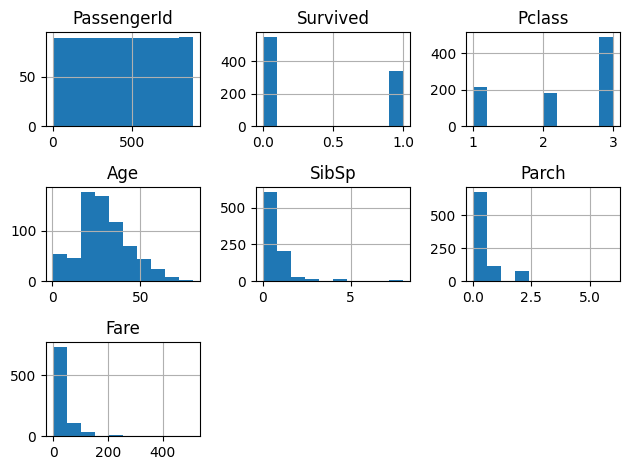

In [164]:
df.hist()
plt.tight_layout()
plt.show()

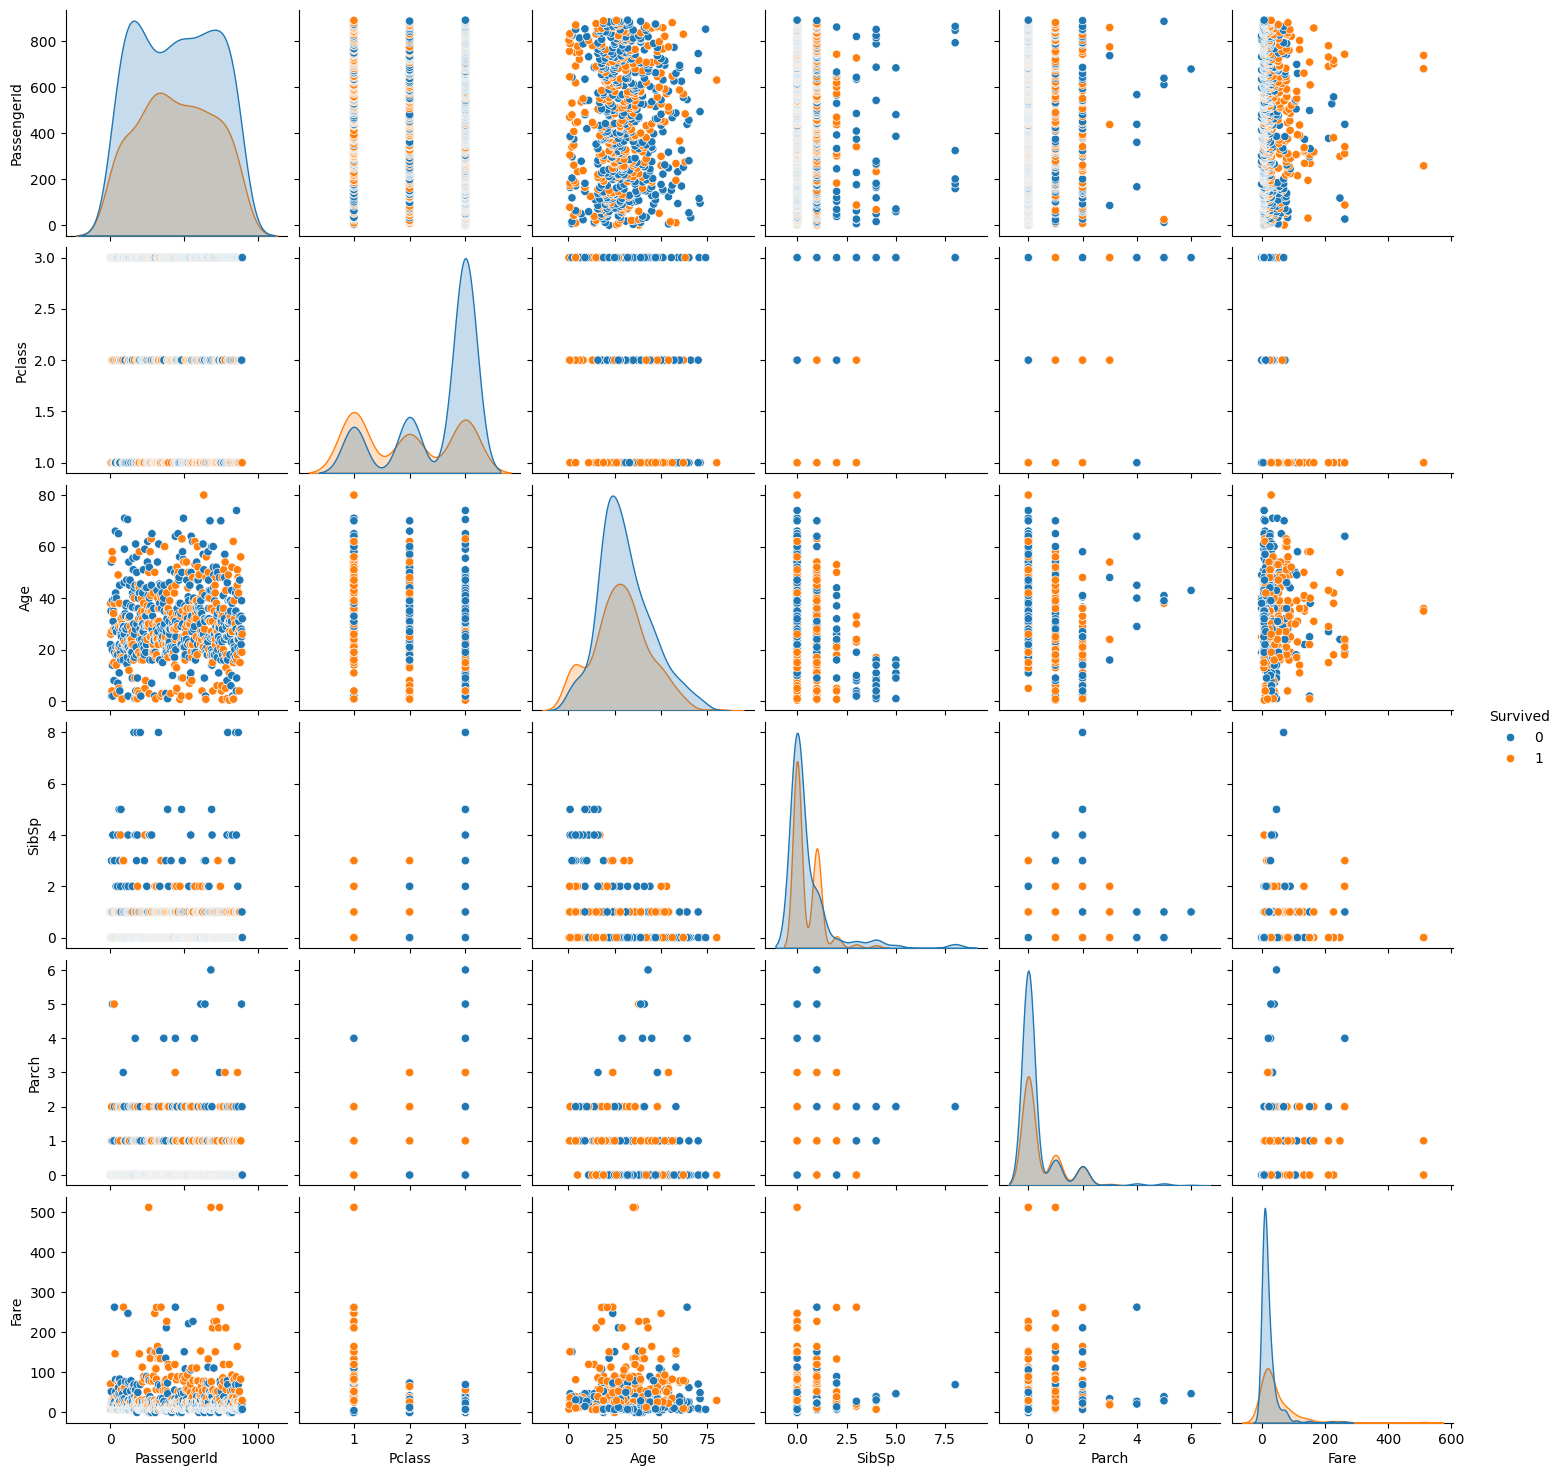

In [165]:
sns.pairplot(df, hue="Survived")

# **Ex 2**

In [166]:
# Ex. 2
df_sex_class = df.groupby(['Sex', 'Pclass'])
print(df_sex_class['Survived'].mean())
print(df_sex_class.describe())

Sex     Pclass
female  1         0.968085
        2         0.921053
        3         0.500000
male    1         0.368852
        2         0.157407
        3         0.135447
Name: Survived, dtype: float64
              PassengerId                                               \
                    count        mean         std   min     25%    50%   
Sex    Pclass                                                            
female 1             94.0  469.212766  247.476723   2.0  293.50  447.0   
       2             76.0  443.105263  243.627288  10.0  269.75  439.5   
       3            144.0  399.729167  267.232416   3.0  165.25  376.0   
male   1            122.0  455.729508  247.026449   7.0  255.50  480.5   
       2            108.0  447.962963  256.922546  18.0  225.75  416.5   
       3            347.0  455.515850  261.921251   1.0  209.50  466.0   

                             Survived            ... Parch        Fare  \
                  75%    max    count      mean  ..

In [167]:
bins = [0, 13, 20, 35, 60, 100]
labels = ['child', 'teenager', 'young', 'adult', 'senior']
df['age_group'] = pd.cut(df['Age'], bins=bins, labels=labels)
survival_age = df.groupby('age_group', observed=False)
print(survival_age.describe())

          PassengerId                                                       \
                count        mean         std   min     25%    50%     75%   
age_group                                                                    
child            71.0  437.549296  278.332113   8.0  183.50  446.0  726.50   
teenager        108.0  444.342593  277.790789  10.0  188.00  426.5  689.25   
young           318.0  445.852201  258.004757   1.0  228.75  428.5  670.75   
adult           195.0  461.210256  246.082087   2.0  252.50  472.0  663.50   
senior           22.0  432.545455  248.225460  34.0  258.75  470.5  612.25   

                 Survived            ... Parch        Fare             \
             max    count      mean  ...   75%  max  count       mean   
age_group                            ...                                
child      870.0     71.0  0.591549  ...   2.0  2.0   71.0  31.024472   
teenager   888.0    108.0  0.370370  ...   0.0  3.0  108.0  29.082988   
young     

In [168]:
age_stats = df.groupby('age_group', observed=False).agg({
    'Survived': 'mean',
    'Fare': ['mean', 'median'],
    'Pclass': 'count'
})
age_stats.columns = ['Survival Rate', 'Avg Fare', 'Median Fare', 'Passenger count']
print(age_stats)

           Survival Rate   Avg Fare  Median Fare  Passenger count
age_group                                                        
child           0.591549  31.024472     26.25000               71
teenager        0.370370  29.082988      9.83335              108
young           0.393082  31.092398     13.00000              318
adult           0.400000  44.259658     26.28750              195
senior          0.227273  41.371214     26.55000               22


/tmp/ipython-input-3008074515.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='age_group', y='Survived', palette='viridis')


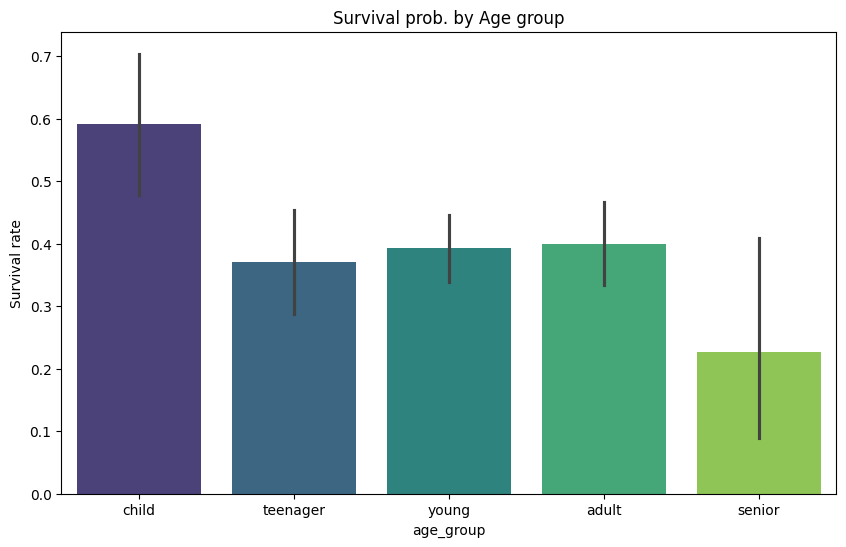

In [169]:
plt.figure(figsize=(10,6))
sns.barplot(data=df, x='age_group', y='Survived', palette='viridis')
plt.title('Survival prob. by Age group')
plt.ylabel('Survival rate')
plt.show()

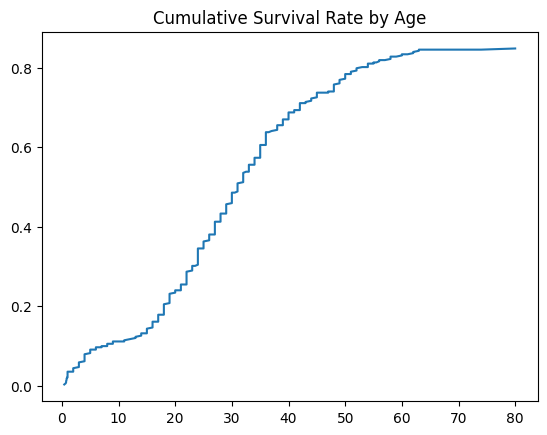

In [170]:
df = df.sort_values('Age')
df['cumulative_survival'] = df['Survived'].cumsum() / df['Survived'].sum()
plt.plot(df['Age'], df['cumulative_survival'])
plt.title('Cumulative Survival Rate by Age')
plt.show()

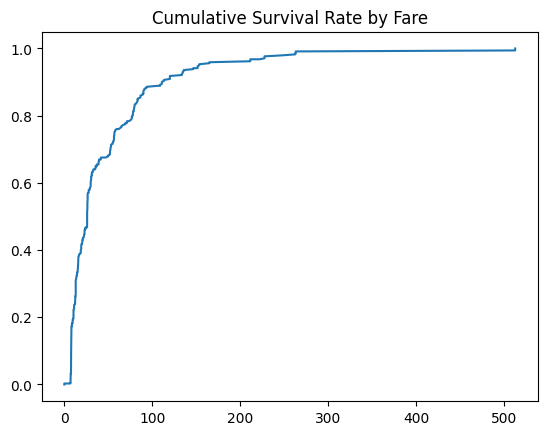

In [171]:
df = df.sort_values('Fare')
df['cumulative_survival'] = df['Survived'].cumsum() / df['Survived'].sum()
plt.plot(df['Fare'], df['cumulative_survival'])
plt.title('Cumulative Survival Rate by Fare')
plt.show()

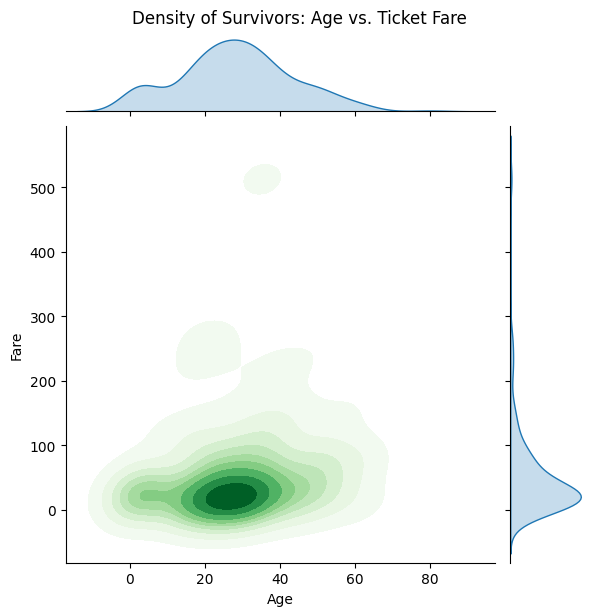

In [172]:
df_age_fare_no_na = df.dropna(subset=['Age','Fare'])
g = sns.jointplot(
    data=df_age_fare_no_na[df_age_fare_no_na['Survived'] == 1],
    x='Age',
    y='Fare',
    kind='kde',
    fill=True,
    cmap="Greens"
)
g.fig.suptitle('Density of Survivors: Age vs. Ticket Fare', y=1.02)
plt.show()

# **Ex 3**

In [173]:
#Ex. 3
unique_counts = df.nunique()
print(unique_counts)
pivot_df = df.pivot_table(index='Sex', columns='Pclass', values='Survived', aggfunc='mean')
print(pivot_df)

PassengerId            891
Survived                 2
Pclass                   3
Name                   891
Sex                      2
Age                     88
SibSp                    7
Parch                    7
Ticket                 681
Fare                   248
Cabin                  147
Embarked                 3
age_group                5
cumulative_survival    343
dtype: int64
Pclass         1         2         3
Sex                                 
female  0.968085  0.921053  0.500000
male    0.368852  0.157407  0.135447


# **Ex 4**

In [174]:
#Ex 4
df.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'], inplace=True)
df.count()

,0
Survived,891
Pclass,891
Sex,891
Age,714
SibSp,891
Parch,891
Fare,891
Embarked,889
age_group,714
cumulative_survival,891


In [175]:
df['Age'] = df['Age'].fillna(df.groupby(['Pclass', 'Sex'])['Age'].transform('median'))
#fill embarked with the most common mode of three modes
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])
df.count()

,0
Survived,891
Pclass,891
Sex,891
Age,891
SibSp,891
Parch,891
Fare,891
Embarked,891
age_group,714
cumulative_survival,891


**Feature engineering**

In [176]:
df['family_size'] = df['SibSp'] + df['Parch']
print(df.count())
df.describe()

Survived               891
Pclass                 891
Sex                    891
Age                    891
SibSp                  891
Parch                  891
Fare                   891
Embarked               891
age_group              714
cumulative_survival    891
family_size            891
dtype: int64


,Survived,Pclass,Age,SibSp,Parch,Fare,cumulative_survival,family_size
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.112424,0.523008,0.381594,32.204208,0.382414,0.904602
std,0.486592,0.836071,13.304424,1.102743,0.806057,49.693429,0.284868,1.613459
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,21.500000,0.000000,0.000000,7.910400,0.130117,0.000000
50%,0.000000,3.000000,26.000000,0.000000,0.000000,14.454200,0.327485,0.000000
75%,1.000000,3.000000,36.000000,1.000000,0.000000,31.000000,0.621345,1.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200,1.000000,10.000000


**Encoding sex for ML**

In [177]:
df['sex_encoded'] = df['Sex'].map({'male': 0, 'female': 1})
df.count()

,0
Survived,891
Pclass,891
Sex,891
Age,891
SibSp,891
Parch,891
Fare,891
Embarked,891
age_group,714
cumulative_survival,891


# **Ex. 5 - Different Supervised classifiers**

In [178]:
#Ex. 5
from sklearn.linear_model import LogisticRegression
from sklearn import svm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import RocCurveDisplay


In [179]:
features = ['Pclass', 'Age', 'family_size', 'Fare', 'sex_encoded']
X = df[features]
y = df['Survived']


In [180]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [181]:
scalar = StandardScaler()
X_train_scaled = scalar.fit_transform(X_train)
X_test_scaled = scalar.transform(X_test)

In [205]:
# Lasso logistic regression
model = LogisticRegression(penalty='l1', solver='liblinear', C=1.0)
model.fit(X_train_scaled, y_train)


LogisticRegression(penalty='l1', solver='liblinear')

In [206]:
print(f"Training accuracy: {model.score(X_train_scaled, y_train): .2f}")
print(f"Testing accuracy: {model.score(X_test_scaled, y_test): .2f}")


Training accuracy:  0.80
Testing accuracy:  0.80


In [207]:
importance = pd.DataFrame({
    'Feature': features,
    'Coefficient': model.coef_[0]
})
print(importance.sort_values(by='Coefficient', ascending=False))


       Feature  Coefficient
4  sex_encoded     1.277073
3         Fare     0.132446
2  family_size    -0.425542
1          Age    -0.572903
0       Pclass    -0.862024


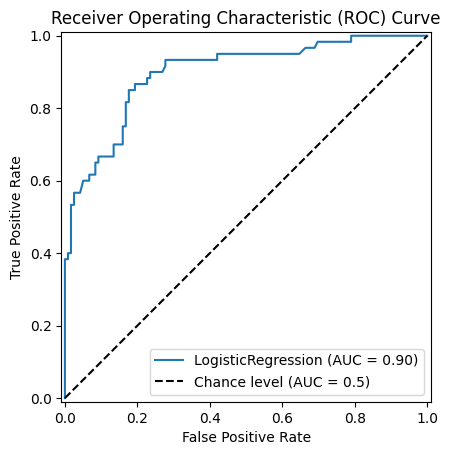

In [208]:
RocCurveDisplay.from_estimator(model, X_test_scaled, y_test)

plt.plot([0, 1], [0, 1], 'k--', label='Chance level (AUC = 0.5)') # Add chance level line
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

In [201]:
# Elasticnet logistic regression
model = LogisticRegression(penalty='elasticnet', solver='saga', l1_ratio=0.5, C=1.0, max_iter=1000)
model.fit(X_train_scaled, y_train)

LogisticRegression(l1_ratio=0.5, max_iter=1000, penalty='elasticnet',
                   solver='saga')

In [202]:
print(f"Training accuracy: {model.score(X_train_scaled, y_train): .2f}")
print(f"Testing accuracy: {model.score(X_test_scaled, y_test): .2f}")


Training accuracy:  0.80
Testing accuracy:  0.80


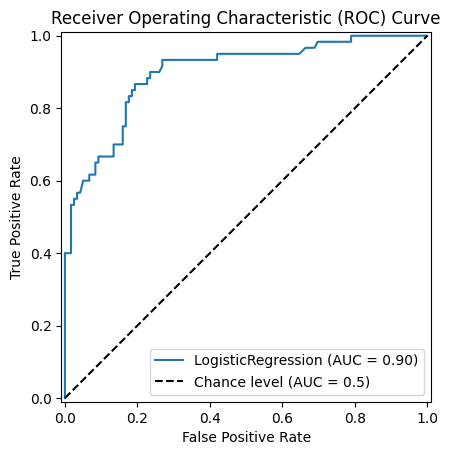

In [204]:
RocCurveDisplay.from_estimator(model, X_test_scaled, y_test)

plt.plot([0, 1], [0, 1], 'k--', label='Chance level (AUC = 0.5)') # Add chance level line
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

In [189]:
# Grid Search
param_grid = {
    'C': [0.001, 0.01, 0.1, 0.2, 0.3, 0.5, 1, 10],
    'l1_ratio': [0.1, 0.5, 0.7, 0.9, 0.95, 1.0]
}
grid_search = GridSearchCV(
    LogisticRegression(penalty='elasticnet', solver='saga', max_iter=10000),
    param_grid,
    cv=4,
    scoring='accuracy'
)

grid_search.fit(X_train_scaled, y_train)

# Print best parameters
print(f"Best parameters: {grid_search.best_params_}")

# Use the best model
best_model = grid_search.best_estimator_


Best parameters: {'C': 0.3, 'l1_ratio': 0.1}


In [190]:
print(f"Training accuracy: {best_model.score(X_train_scaled, y_train): .2f}")
print(f"Testing accuracy: {best_model.score(X_test_scaled, y_test): .2f}")


Training accuracy:  0.80
Testing accuracy:  0.80


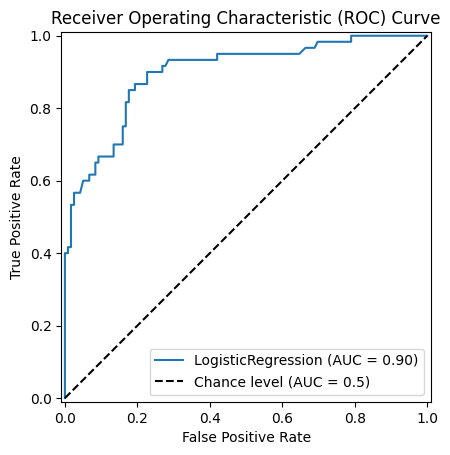

In [200]:
RocCurveDisplay.from_estimator(best_model, X_test_scaled, y_test)

plt.plot([0, 1], [0, 1], 'k--', label='Chance level (AUC = 0.5)') # Add chance level line
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

In [209]:
# SVM
model = svm.SVC(kernel='linear', C=1)
model.fit(X_train_scaled, y_train)

SVC(C=1, kernel='linear')

In [210]:
print(f"Training accuracy: {model.score(X_train_scaled, y_train): .2f}")
print(f"Testing accuracy: {model.score(X_test_scaled, y_test): .2f}")


Training accuracy:  0.78
Testing accuracy:  0.80


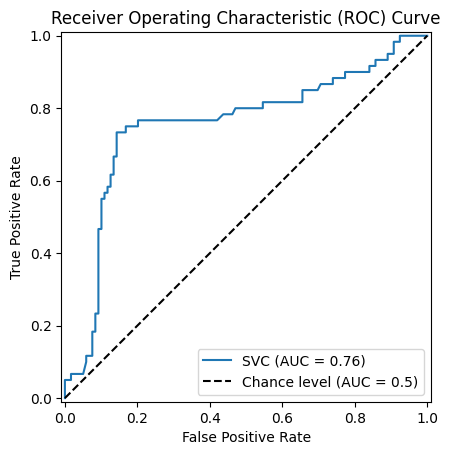

In [211]:
RocCurveDisplay.from_estimator(model, X_test_scaled, y_test)

plt.plot([0, 1], [0, 1], 'k--', label='Chance level (AUC = 0.5)') # Add chance level line
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()


In [218]:
# KNN
model = KNeighborsClassifier(n_neighbors=8)
model.fit(X_train_scaled, y_train)

KNeighborsClassifier(n_neighbors=8)

In [219]:
print(f"Training accuracy: {model.score(X_train_scaled, y_train): .2f}")
print(f"Testing accuracy: {model.score(X_test_scaled, y_test): .2f}")


Training accuracy:  0.84
Testing accuracy:  0.83


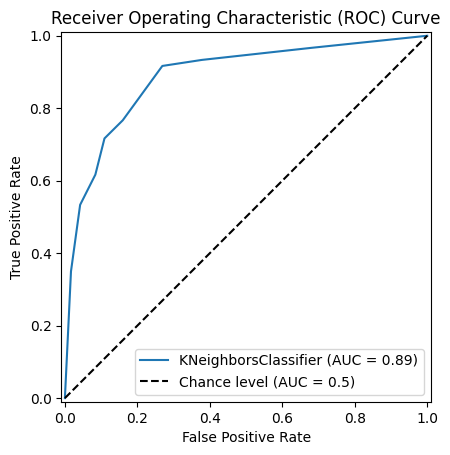

In [220]:
RocCurveDisplay.from_estimator(model, X_test_scaled, y_test)

plt.plot([0, 1], [0, 1], 'k--', label='Chance level (AUC = 0.5)') # Add chance level line
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

# **Ex 6**

In [221]:
first_class_teens = df[(df['Pclass'] == 1) & (df['age_group'] == 'teenager')]
print(first_class_teens.describe())
first_class_teens.count()

        Survived  Pclass        Age      SibSp      Parch        Fare  \
count  17.000000    17.0  17.000000  17.000000  17.000000   17.000000   
mean    0.823529     1.0  17.352941   0.705882   0.882353  113.759559   
std     0.392953     0.0   1.538716   0.848875   0.927520   78.878253   
min     0.000000     1.0  14.000000   0.000000   0.000000   26.283300   
25%     1.000000     1.0  16.000000   0.000000   0.000000   57.000000   
50%     1.000000     1.0  18.000000   1.000000   1.000000   91.079200   
75%     1.000000     1.0  19.000000   1.000000   2.000000  120.000000   
max     1.000000     1.0  19.000000   3.000000   2.000000  263.000000   

       cumulative_survival  family_size  sex_encoded  
count            17.000000    17.000000    17.000000  
mean              0.827485     1.588235     0.764706  
std               0.138762     1.325652     0.437237  
min               0.532164     0.000000     0.000000  
25%               0.751462     1.000000     1.000000  
50%         

,0
Survived,17
Pclass,17
Sex,17
Age,17
SibSp,17
Parch,17
Fare,17
Embarked,17
age_group,17
cumulative_survival,17
